# Citation linking tryings

An experiment workbench for `yurui983/citation_linking`, configuration **reference_index_disjoint**.

1. Retrieve up to **10 candidates** for every `(ref_id, index)` using the existing metadata-search connectors; save complete returned metadata locally.
2. Score future model/decision outputs against the gold IDs using shared helpers. No model selection or LLM calls are included yet.

All train/validation/test assignments are preserved. Tune on validation and reserve test for the final comparison. This protocol can place the same reference in different splits for different indexes, so shared-model results should distinguish references seen and unseen during training.

**Latest results (20 October 2026): see Section 6.** It uses corrected private dataset revision `598fb258f3cfed7781167b7f595e3536c3e2f660` and the frozen search results. Sections 0–5 retain the earlier revision as an experiment history. Five unavailable OpenAlex targets are now null and one has a verified replacement; all rows and splits are preserved. Those five nulls are unresolved catalogue cases, not confirmed negatives for future decision-model evaluation.


## 0. Setup


In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
from datetime import datetime, timezone

import pandas as pd
import pyarrow.parquet as pq
from dotenv import load_dotenv
from huggingface_hub import hf_hub_download
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/citation_index").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
load_dotenv(ROOT / ".env", override=False)

from citation_index.core.connectors import OpenAlexConnector, MatildaConnector, WikidataConnector
from benchmarks.citation_linking.citation_link_tryings_helpers import (
    retrieve_candidates, retrieval_scores, score_predictions, summarize_scores,
)

DATASET_ID = "yurui983/citation_linking"
CONFIG = "reference_index_disjoint"
SPLITS = ("train", "validation", "test")
TOP_K = 10
DATASET_REVISION = "15241271859eaa4d3c06a49cc85743c495cc902b"
RETRIEVAL_SOURCE = ROOT / "logs/citation_link_tryings" / CONFIG
OUTPUT = RETRIEVAL_SOURCE / f"evaluation_{DATASET_REVISION[:12]}"
OUTPUT.mkdir(parents=True, exist_ok=True)
# Set a path explicitly for an offline release; None loads the published Hub dataset.
LOCAL_RELEASE = None  # Example: ROOT / "logs/citation_linking_release"

### Load the reviewed dataset release

In [2]:
revision_path = OUTPUT / "dataset_revision.json"
if LOCAL_RELEASE is None:
    revision = DATASET_REVISION
    revision_path.write_text(json.dumps({
        "dataset_id": DATASET_ID, "config": CONFIG, "revision": revision,
    }, indent=2))
    paths = {
        split: Path(hf_hub_download(
            DATASET_ID, f"{CONFIG}/{split}.parquet", repo_type="dataset",
            revision=revision, local_dir=OUTPUT / "dataset",
        )) for split in SPLITS
    }
else:
    revision = "local"
    paths = {split: Path(LOCAL_RELEASE) / CONFIG / f"{split}.parquet" for split in SPLITS}

tasks = pd.concat([
    pd.DataFrame(pq.read_table(path).to_pylist()).assign(split=split)
    for split, path in paths.items()
], ignore_index=True)
assert not tasks.duplicated(["ref_id", "index"]).any()
assert set(tasks["index"]) == {"openalex", "matilda", "wikidata"}
train_refs = set(tasks.loc[tasks["split"].eq("train"), "ref_id"])
tasks["seen_reference_in_train"] = tasks["ref_id"].isin(train_refs)
tasks.to_json(OUTPUT / "tasks.jsonl", orient="records", lines=True, force_ascii=False)
display(tasks.groupby(["split", "index"]).agg(
    tasks=("ref_id", "size"), gold_targets=("gold_id", "count"),
))
(OUTPUT / "evaluation_manifest.json").write_text(json.dumps({
    "dataset_id": DATASET_ID, "config": CONFIG, "revision": revision,
    "local_release": str(LOCAL_RELEASE) if LOCAL_RELEASE else None,
    "input_sha256": {split: hashlib.sha256(path.read_bytes()).hexdigest()
                     for split, path in paths.items()},
    "retrieval_source": str(RETRIEVAL_SOURCE),
    "evaluated_at": datetime.now(timezone.utc).isoformat(),
}, indent=2))


tasks  gold_targets
split      index                        
test       matilda      96            25
           openalex     96            42
           wikidata     96            23
train      matilda     289            79
           openalex    288           126
           wikidata    288            72
validation matilda      96            26
           openalex     97            42
           wikidata     97            24

615

### Metadata search and checkpoints

Use the supplied parsed title; where absent, use the raw reference as the title query and mark `query_mode="raw_reference"`. Gold IDs and DOIs are never sent to search. OpenAlex and Matilda use their existing title searches; Wikidata uses its existing title search, heuristic ordering, and entity-details fetch. Rank is the connector's returned order, not a common cross-index relevance score. Fewer than ten candidates is valid.

`searches.jsonl` contains one row per task, with query, timestamp, count and nested `candidates`. Each candidate stores its rank, normalized ID and full returned `metadata`. Per-task JSON checkpoints are under `checkpoints/`. Cache keys include query, top-k and retrieval code hash, so changing retrieval code cannot silently reuse old results.

A completed `RETRIEVAL_SOURCE/searches.jsonl` is reused as the frozen initial snapshot. Search improvements are evaluated in a separate validation section below. Choose a new retrieval source directory for a fresh full-dataset retrieval.

In [3]:
if (RETRIEVAL_SOURCE / "searches.jsonl").exists():
    searches = pd.read_json(RETRIEVAL_SOURCE / "searches.jsonl", lines=True, convert_dates=False)
    print(f"Reusing frozen initial snapshot: {len(searches)} searches")
    (OUTPUT / "manifest.json").write_text((RETRIEVAL_SOURCE / "manifest.json").read_text())
else:
    code_paths = sorted((ROOT / "src/citation_index").rglob("*.py")) + [
        ROOT / "benchmarks/citation_linking/citation_link_tryings_helpers.py",
        ROOT / "benchmarks/citation_linking/build_annotation_dataset.py",
    ]
    code_hash = hashlib.sha256(b"".join(
        str(path.relative_to(ROOT)).encode() + path.read_bytes() for path in code_paths
    )).hexdigest()
    manifest = {
        "dataset_id": DATASET_ID, "config": CONFIG, "revision": revision,
        "local_release": str(LOCAL_RELEASE) if LOCAL_RELEASE else None,
        "input_sha256": {split: hashlib.sha256(path.read_bytes()).hexdigest()
                         for split, path in paths.items()},
        "top_k": TOP_K, "retrieval_code_sha256": code_hash,
        "started_at": datetime.now(timezone.utc).isoformat(),
        "python": sys.version, "pandas": pd.__version__,
    }
    (OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2))
    connectors = {
        "openalex": OpenAlexConnector(),
        "matilda": MatildaConnector(),
        "wikidata": WikidataConnector(),
    }
    searches = retrieve_candidates(
        tasks, connectors, OUTPUT / "checkpoints", top_k=TOP_K,
        retrieval_version=code_hash,
    )
    searches.to_json(OUTPUT / "searches.jsonl", orient="records", lines=True, force_ascii=False)
    print(f"Saved {len(searches)} searches to {OUTPUT}")
searches.to_json(OUTPUT / "searches.jsonl", orient="records", lines=True, force_ascii=False)


Reusing frozen initial snapshot: 1443 searches


### Load cached metadata with pandas

The task table includes supervision; the candidate table does not. Pass only reference inputs and candidate metadata to future decision models. The flattened JSONL is convenient for one-candidate-per-row analysis; zero-candidate tasks remain visible in `searches.jsonl` and `tasks.jsonl`.

For later offline experiments, run Setup and resume at this cell, skipping the dataset-loading and search cells.

In [4]:
tasks = pd.read_json(OUTPUT / "tasks.jsonl", lines=True, convert_dates=False)
searches = pd.read_json(OUTPUT / "searches.jsonl", lines=True, convert_dates=False)
candidate_rows = [
    {"ref_id": row.ref_id, "index": row.index, **candidate}
    for row in searches.itertuples() for candidate in row.candidates
]
candidates = pd.DataFrame(candidate_rows, columns=["ref_id", "index", "rank", "candidate_id", "metadata"])
candidates = candidates.merge(tasks[["ref_id", "index", "split"]], on=["ref_id", "index"], validate="many_to_one")
candidates.to_json(OUTPUT / "candidates.jsonl", orient="records", lines=True, force_ascii=False)
display(candidates[["ref_id", "index", "split", "rank", "candidate_id"]].head(10))
# Example: candidates.iloc[0]["metadata"] exposes the full provider record.

,ref_id,index,split,rank,candidate_id
0,10.1111_1467-6478.00057_instance-11,openalex,train,1,W1594834420
1,10.1111_1467-6478.00057_instance-11,openalex,train,2,W3144072753
2,10.1111_1467-6478.00057_instance-11,openalex,train,3,W2612659921
3,10.1111_1467-6478.00057_instance-11,openalex,train,4,W2583501972
4,10.1111_1467-6478.00057_instance-11,openalex,train,5,W4396977630
5,10.1111_1467-6478.00057_instance-11,openalex,train,6,W2775281730
6,10.1111_1467-6478.00057_instance-11,openalex,train,7,W2963566055
7,10.1111_1467-6478.00057_instance-11,openalex,train,8,W2623548629
8,10.1111_1467-6478.00057_instance-11,openalex,train,9,W1554391032
9,10.1111_1467-6478.00057_instance-11,openalex,train,10,W3122658976


### Check retrieval coverage

Recall@10 and MRR@10 use only tasks with a non-null gold ID. A missing gold candidate is a retrieval miss; a null gold ID is an annotation saying no target was found in that index. Neither a failed request nor a missing prediction is treated as abstention.

In [5]:
retrieval = retrieval_scores(tasks, searches)
retrieval_summary = retrieval.groupby(["split", "index"])[["n_candidates", "gold_id", "gold_rank"]].apply(
    lambda group: pd.Series({
        "tasks": len(group),
        "zero_candidates": group["n_candidates"].eq(0).sum(),
        "gold_targets": group["gold_id"].notna().sum(),
        "gold_retrieved": group["gold_rank"].notna().sum(),
        "recall_at_10": group.loc[group["gold_id"].notna(), "gold_rank"].notna().mean(),
        "mrr_at_10": (1 / group.loc[group["gold_id"].notna(), "gold_rank"]).fillna(0).mean(),
    }),
)
retrieval_summary.to_csv(OUTPUT / "retrieval_scores.csv")
display(retrieval_summary.round(4))

tasks  zero_candidates  gold_targets  gold_retrieved  \
split      index                                                            
test       matilda    96.0             47.0          25.0            22.0   
           openalex   96.0             14.0          42.0            36.0   
           wikidata   96.0             81.0          23.0            13.0   
train      matilda   289.0            146.0          79.0            69.0   
           openalex  288.0             31.0         126.0            98.0   
           wikidata  288.0            238.0          72.0            33.0   
validation matilda    96.0             50.0          26.0            22.0   
           openalex   97.0              9.0          42.0            35.0   
           wikidata   97.0             82.0          24.0             9.0   

                     recall_at_10  mrr_at_10  
split      index                              
test       matilda         0.8800     0.8267  
           openalex        0.8571     0.8095  
           wikidata        0.5652     0.5435  
train      matilda         0.8734     0.8017  
           openalex        0.7778     0.7526  
           wikidata        0.4583     0.4444  
validation matilda         0.8462     0.8013  
           openalex        0.8333     0.8333  
           wikidata        0.3750     0.3750

### Reusable decision scoring

Provide a DataFrame with **exactly one** `ref_id`, `index`, `predicted_id` row per evaluated task. `predicted_id=None` means explicit abstention. Missing, extra or duplicate task keys are errors. URL and short-ID forms are normalized with the dataset builder's validator; scores use index IDs, not DOI equality.

`score_predictions(tasks, predictions)` produces the five annotation outcomes. `summarize_scores(scored, by=("split", "index"))` reuses the existing annotation metrics, including precision, recall, F1, accuracy, counts and Wilson intervals. Wrong links count as both FP and FN. F1 uses `2TP / (2TP + FP + FN)` so complete failure scores zero; metrics with no denominator are undefined (`NaN`/`None`). `by=()` gives an overall micro aggregate; use `by=("split", "index", "source")` for corpus breakdowns.

The following **always-abstain sanity baseline** demonstrates the interface; it is not a model experiment.

In [6]:
predictions = tasks[["ref_id", "index"]].assign(predicted_id=None)
scored = score_predictions(tasks, predictions)
baseline_scores = summarize_scores(scored)
display(baseline_scores[["split", "index", "n_eval", "precision", "recall", "f1", "accuracy"]])
assert scored["outcome"].eq("correct_abstain").sum() == tasks["gold_id"].isna().sum()
assert scored["outcome"].eq("missed_link").sum() == tasks["gold_id"].notna().sum()

# Future model example (score only the rows that model evaluated):
# validation = tasks.loc[tasks["split"].eq("validation")]
# predictions = pd.read_json("my_model_validation_predictions.jsonl", lines=True)
# scored = score_predictions(validation, predictions)
# display(summarize_scores(scored))
# display(summarize_scores(scored, by=("split", "index", "source")))
# For a model trained across indexes, also report seen/unseen-reference results:
# display(summarize_scores(scored, by=("split", "seen_reference_in_train")))

,split,index,n_eval,precision,recall,f1,accuracy
0,test,matilda,96,None,0.0,0.0,0.739583
1,test,openalex,96,None,0.0,0.0,0.562500
2,test,wikidata,96,None,0.0,0.0,0.760417
3,train,matilda,289,None,0.0,0.0,0.726644
4,train,openalex,288,None,0.0,0.0,0.562500
5,train,wikidata,288,None,0.0,0.0,0.750000
6,validation,matilda,96,None,0.0,0.0,0.729167
7,validation,openalex,97,None,0.0,0.0,0.567010
8,validation,wikidata,97,None,0.0,0.0,0.752577


## 3. Improve search on validation data

This iteration preserves Unicode letters and separates punctuation into word boundaries. Wikidata keeps its entity-search candidates and fills remaining slots with deduplicated full-text results; final candidate lists still contain at most 10 records. Matilda explicitly distinguishes its `{"total": 0}` empty response from malformed responses. OpenAlex keeps broad search and includes both core and expansion records with `corpus=all`. A title-only trial recovered fewer validation targets. See the [OpenAlex corpus documentation](https://help.openalex.org/data/works/corpus/) and [Wikidata entity-search documentation](https://www.mediawiki.org/wiki/Wikibase/API).

The experiment uses **validation only**, with the corrected dataset labels applied to both candidate snapshots. Gold labels are used only for scoring, never to construct a query or choose a fallback. The initial snapshot remains unchanged; rescored tables are saved under the revision-specific `evaluation_.../search_v3_validation/` directory. The comparison is against a cached live-index snapshot, so changes in provider data between runs are also possible.

Run Setup and the cached-data loading cell first if continuing from an existing cache. No model decisions or test-set rerun are involved.

Completed experiment snapshots are reused on rerun. Choose a new `EXPERIMENT_SOURCE` directory for a different search strategy; incomplete runs use code-aware per-task checkpoints.

In [7]:
validation_tasks = tasks.loc[tasks["split"].eq("validation")].copy()
EXPERIMENT_OUTPUT = OUTPUT / "search_v3_validation"
EXPERIMENT_OUTPUT.mkdir(parents=True, exist_ok=True)
EXPERIMENT_SOURCE = RETRIEVAL_SOURCE / "search_v3_validation"
if (EXPERIMENT_SOURCE / "searches.jsonl").exists():
    improved_searches = pd.read_json(EXPERIMENT_SOURCE / "searches.jsonl", lines=True, convert_dates=False)
    print("Rescoring completed validation snapshot against the pinned dataset release.")
    (EXPERIMENT_OUTPUT / "manifest.json").write_text((EXPERIMENT_SOURCE / "manifest.json").read_text())
else:
    retrieval_code_paths = sorted((ROOT / "src/citation_index").rglob("*.py")) + [
        ROOT / "benchmarks/citation_linking/citation_link_tryings_helpers.py",
        ROOT / "benchmarks/citation_linking/build_annotation_dataset.py",
    ]
    retrieval_code_hash = hashlib.sha256(b"".join(
        str(path.relative_to(ROOT)).encode() + path.read_bytes() for path in retrieval_code_paths
    )).hexdigest()
    experiment_manifest = {
        "config": CONFIG, "split": "validation", "top_k": TOP_K,
        "dataset": json.loads((OUTPUT / "dataset_revision.json").read_text()),
        "baseline_manifest": json.loads((OUTPUT / "manifest.json").read_text()),
        "retrieval_code_sha256": retrieval_code_hash,
        "started_at": datetime.now(timezone.utc).isoformat(),
    }
    (EXPERIMENT_OUTPUT / "manifest.json").write_text(json.dumps(experiment_manifest, indent=2))
    improved_searches = retrieve_candidates(
        validation_tasks,
        {"openalex": OpenAlexConnector(), "matilda": MatildaConnector(), "wikidata": WikidataConnector()},
        EXPERIMENT_OUTPUT / "checkpoints", top_k=TOP_K,
        retrieval_version=retrieval_code_hash,
    )
improved_searches.to_json(EXPERIMENT_OUTPUT / "searches.jsonl", orient="records", lines=True, force_ascii=False)
improved_candidates = pd.DataFrame([
    {"ref_id": row.ref_id, "index": row.index, "split": "validation", **candidate}
    for row in improved_searches.itertuples() for candidate in row.candidates
], columns=["ref_id", "index", "split", "rank", "candidate_id", "metadata"])
improved_candidates.to_json(EXPERIMENT_OUTPUT / "candidates.jsonl", orient="records", lines=True, force_ascii=False)
print(f"Saved {len(improved_searches)} validation searches to {EXPERIMENT_OUTPUT}")

Rescoring completed validation snapshot against the pinned dataset release.


Saved 290 validation searches to /Users/alex/docs/code/Odoma/citation_index/logs/citation_link_tryings/reference_index_disjoint/evaluation_15241271859e/search_v3_validation


In [8]:
baseline_validation = searches.merge(validation_tasks[["ref_id", "index"]], on=["ref_id", "index"], validate="one_to_one")
before = retrieval_scores(validation_tasks, baseline_validation)
after = retrieval_scores(validation_tasks, improved_searches)

def retrieval_summary_by_index(frame):
    summary = frame.assign(
        has_gold=frame["gold_id"].notna(),
        hit=frame["gold_rank"].notna(),
        empty=frame["n_candidates"].eq(0),
        reciprocal_rank=(1 / frame["gold_rank"]).fillna(0),
    ).groupby("index").agg(
        tasks=("ref_id", "size"), gold_targets=("has_gold", "sum"),
        gold_retrieved=("hit", "sum"), zero_candidates=("empty", "sum"),
        reciprocal_rank_sum=("reciprocal_rank", "sum"),
    )
    summary["recall_at_10"] = summary["gold_retrieved"] / summary["gold_targets"]
    summary["mrr_at_10"] = summary.pop("reciprocal_rank_sum") / summary["gold_targets"]
    return summary

comparison = retrieval_summary_by_index(before).join(
    retrieval_summary_by_index(after), lsuffix="_before", rsuffix="_after",
)
comparison.to_csv(EXPERIMENT_OUTPUT / "comparison.csv")
display(comparison[["gold_targets_before", "gold_retrieved_before", "gold_retrieved_after", "recall_at_10_before", "recall_at_10_after", "mrr_at_10_before", "mrr_at_10_after"]].round(4))

,gold_targets_before,gold_retrieved_before,gold_retrieved_after,recall_at_10_before,recall_at_10_after,mrr_at_10_before,mrr_at_10_after
index,,,,,,,
matilda,26,22,25,0.8462,0.9615,0.8013,0.9167
openalex,42,35,38,0.8333,0.9048,0.8333,0.8730
wikidata,24,9,22,0.3750,0.9167,0.3750,0.8750


In [9]:
changes = before[["ref_id", "index", "source", "reference", "gold_id", "gold_rank"]].merge(
    after[["ref_id", "index", "gold_rank"]], on=["ref_id", "index"],
    suffixes=("_before", "_after"), validate="one_to_one",
)
changes["recovered"] = changes["gold_rank_before"].isna() & changes["gold_rank_after"].notna()
changes["lost"] = changes["gold_rank_before"].notna() & changes["gold_rank_after"].isna()
changes.to_json(EXPERIMENT_OUTPUT / "per_task_comparison.jsonl", orient="records", lines=True, force_ascii=False)
display(changes.groupby("index")[["recovered", "lost"]].sum())
# Inspect remaining misses without feeding gold labels into retrieval:
remaining_misses = changes.loc[changes["gold_id"].notna() & changes["gold_rank_after"].isna()]
display(remaining_misses[["ref_id", "index", "reference"]].head(12))
# Show the approved targets against the unchanged candidate snapshots.
approved_refs = ["cex_PHY-AST_96_10", "excite_9543_52"]
display(changes.loc[
    changes["index"].eq("openalex") & changes["ref_id"].isin(approved_refs),
    ["ref_id", "gold_id", "gold_rank_before", "gold_rank_after"],
])


,recovered,lost
index,,
matilda,3,0
openalex,3,0
wikidata,13,0


,ref_id,index,reference
69,brill_5b7ade43-7b83-4597-a458-042d8a99632f_64,wikidata,"——, ‘ Why are institutions the “Carriers of hi..."
98,brill_c90e527d-b3cc-4ae0-b2c5-f959ba70584e_106,openalex,"Frawley, William. Linguistic Semantics. Hillsd..."
114,cex_ART-HUM_7_19,wikidata,"F Simons, D Fennig. Ethnologue: Languages of t..."
145,cex_ENV-SCI_54_70,matilda,"D Reike, W J Vermeulen, S Witjes. The circular..."
225,excite_9543_52,openalex,"Ringmar, Erik (1996). Identity, interest and a..."
242,linkedbook_21,openalex,"Solomon, Harry. “ The Rhetoric of ‘ Redressing..."
259,linkedbook_48,openalex,CECCHETTI B.: La vita dei veneziani nel 1300. ...


,ref_id,gold_id,gold_rank_before,gold_rank_after
155,cex_PHY-AST_96_10,W1968542656,1.0,1.0
225,excite_9543_52,W4233971661,NaN,NaN


## 6. Final search and reranking data

The earlier baseline and validation blocks above are preserved as historical snapshots. This section is the current handoff; it uses private dataset revision **`598fb258f3cfed7781167b7f595e3536c3e2f660`**, configuration `reference_index_disjoint`, with **1,443 tasks** (481 per index) and **454 non-null gold targets**. All original split assignments remain intact.

### Production search method

The three connectors' `search(reference, top_k=10)` methods return the tested combined candidates. The linking pipeline consumes this search directly; its final matching rules and identifier lookup are unchanged.

| Index | Ordered search paths |
|---|---|
| OpenAlex | General search with normalized full title; quoted opening-title search via `search.title`; general search with normalized full title plus first-author surname |
| Matilda | `query.title` using normalized full title, raw title with case/punctuation intact, and normalized opening title |
| Wikidata | The same three title variants; each performs entity-label search, existing metadata scoring against the original reference, then full-text search to fill spare slots |

Normalization preserves Unicode letters and marks, lowercases, and replaces punctuation with spaces. The opening title is the text before the first `.`, `:`, `!`, or `?`; clauses with fewer than three normalized tokens fall back to the full title. Identical queries are reused. OpenAlex searches the full corpus in API relevance order and omits a redundant author query when no surname is available. Matilda retains caller-supplied filters. Wikidata retains the original reference for language detection and scoring.

Each path retrieves up to ten results. We interleave the ordered lists round-robin, deduplicate by provider ID, and stop at ten. An API failure raises an error instead of yielding an empty or partial success. The benchmark uses the parsed title, falling back to the original citation when absent; gold IDs/DOIs never enter these search queries.

### Two local files

- **A — `logs/citation_link_tryings/search_top10.jsonl`:** the frozen combined top-ten candidates, including full provider metadata and tasks with zero results.
- **B — `logs/citation_link_tryings/search_perfect.jsonl`:** the same rows and candidate order, appending the exact gold record only when a non-null gold ID was missed. All retrieved candidates remain, so an affected row can contain **eleven** candidates. This is an oracle candidate pool for reranking, not a search-recall result.

Both files contain one row per `(ref_id, index)`, the original reference and parsed fields, split, dataset revision, gold supervision, and nested `candidates` with `rank`, `candidate_id`, and `metadata`. Injection provenance is in the row-level `injected_gold_id` and `injected_metadata_source` fields. Use only reference inputs and candidate metadata for a decision model; keep gold/provenance fields out of its inputs. Shuffle candidate order consistently for oracle reranking to avoid leaking the appended gold position.

The frozen queries ran on 16–17 October (OpenAlex) and 19 October (Matilda/Wikidata). Production code was checked against all 1,443 cached searches for identical candidate IDs and order. Missing gold metadata comes from saved exact-ID diagnostics or Matilda's exact-ID lookup; IDs are verified before injection. Rebuild both files offline with `conda run -n citation_index python benchmarks/citation_linking/build_reranking_data.py`. Historical checkpoints and reports are retained under `logs/citation_link_tryings/archive/`.

In [10]:
RERANKING_DIR = ROOT / "logs/citation_link_tryings"
retrieved = pd.read_json(RERANKING_DIR / "search_top10.jsonl", lines=True, convert_dates=False)
perfect = pd.read_json(RERANKING_DIR / "search_perfect.jsonl", lines=True, convert_dates=False)
assert len(retrieved) == len(perfect) == 1443
assert retrieved[["ref_id", "index", "split", "gold_id"]].equals(perfect[["ref_id", "index", "split", "gold_id"]])
assert retrieved["dataset_revision"].eq("598fb258f3cfed7781167b7f595e3536c3e2f660").all()
assert retrieved["n_candidates"].le(10).all() and perfect["n_candidates"].le(11).all()
assert retrieved["injected_gold_id"].isna().all()
assert perfect["injected_gold_id"].notna().sum() == 31
for original, completed in zip(retrieved.itertuples(), perfect.itertuples()):
    assert completed.candidates[:len(original.candidates)] == original.candidates
    assert len({c["candidate_id"] for c in completed.candidates}) == len(completed.candidates)
    assert pd.isna(completed.gold_id) or completed.gold_id in [c["candidate_id"] for c in completed.candidates]
print("Validated 1,443 tasks; 31 verified gold records appended.")
display(retrieved[["ref_id", "index", "split", "gold_id", "n_candidates"]].head())

Validated 1,443 tasks; 31 verified gold records appended.


,ref_id,index,split,gold_id,n_candidates
0,10.1111_1467-6478.00057_instance-1,wikidata,train,None,6
1,10.1111_1467-6478.00057_instance-11,matilda,train,None,0
2,10.1111_1467-6478.00057_instance-11,openalex,train,W1594834420,10
3,10.1111_1467-6478.00057_instance-11,wikidata,train,None,0
4,10.1111_1467-6478.00057_instance-12,matilda,train,None,10


### Search quality and oracle coverage

Recall@10 counts positive-gold tasks with the exact target in the ten results. MRR@10 averages reciprocal rank over the same positive tasks; misses contribute zero. Null-gold rows are counted but excluded from these denominators. The five manually cleared OpenAlex targets are unresolved catalogue cases, not confirmed negative examples for future abstention scoring.

Combined retrieval recovers **423/454 targets (93.17%)**. Against the normalized-title baseline on the same corrected labels it gains six OpenAlex, five Matilda, and seven Wikidata targets without losing a hit. OpenAlex lowers 11 existing ranks: test recall remains 39/40, while MRR drops from 0.9000 to 0.8792. Matilda lowers no existing ranks; Wikidata improves two and lowers none. The combination is selected for candidate recall, not guaranteed rank improvement.

These are exploratory results: all splits, including test, have been inspected. Matilda/Wikidata combinations used roughly twice the measured HTTP work. Future model evaluation should preserve splits and distinguish references shared across index-specific splits.

In [11]:
task_columns = ["ref_id", "index", "split", "gold_id"]
final_scores = retrieval_scores(retrieved[task_columns], retrieved)

def summarize_final(frame, by):
    grouped = frame.assign(
        has_gold=frame.gold_id.notna(), hit=frame.gold_rank.notna(),
        reciprocal_rank=(1 / frame.gold_rank).fillna(0),
    ).groupby(by).agg(
        tasks=("ref_id", "size"), gold_targets=("has_gold", "sum"),
        gold_retrieved=("hit", "sum"), reciprocal_rank_sum=("reciprocal_rank", "sum"),
    )
    grouped["recall_at_10"] = grouped.gold_retrieved / grouped.gold_targets
    grouped["mrr_at_10"] = grouped.pop("reciprocal_rank_sum") / grouped.gold_targets
    return grouped

final_summary = summarize_final(final_scores, ["index"])
display(final_summary.round(4))
display(summarize_final(final_scores, ["index", "split"]).round(4))
coverage = final_summary[["tasks", "gold_targets", "gold_retrieved"]].copy()
coverage["gold_injected"] = perfect.assign(injected=perfect.injected_gold_id.notna()).groupby("index").injected.sum()
coverage["perfect_gold_coverage"] = (coverage.gold_retrieved + coverage.gold_injected) / coverage.gold_targets
display(coverage)

,tasks,gold_targets,gold_retrieved,recall_at_10,mrr_at_10
index,,,,,
matilda,481,130,122,0.9385,0.8718
openalex,481,205,192,0.9366,0.8688
wikidata,481,119,109,0.9160,0.8658


tasks  gold_targets  gold_retrieved  recall_at_10  \
index    split                                                           
matilda  test           96            25              24        0.9600   
         train         289            79              72        0.9114   
         validation     96            26              26        1.0000   
openalex test           96            40              39        0.9750   
         train         288           123             111        0.9024   
         validation     97            42              42        1.0000   
wikidata test           96            23              20        0.8696   
         train         288            72              66        0.9167   
         validation     97            24              23        0.9583   

                     mrr_at_10  
index    split                  
matilda  test           0.9067  
         train          0.8333  
         validation     0.9551  
openalex test           0.8792  
         train          0.8487  
         validation     0.9177  
wikidata test           0.8261  
         train          0.8616  
         validation     0.9167

,tasks,gold_targets,gold_retrieved,gold_injected,perfect_gold_coverage
index,,,,,
matilda,481,130,122,8,1.0
openalex,481,205,192,13,1.0
wikidata,481,119,109,10,1.0


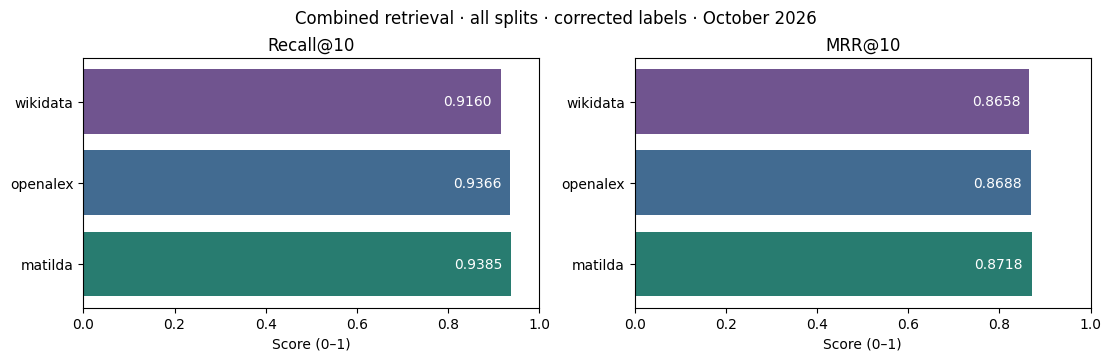

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
for ax, metric, title in zip(axes, ["recall_at_10", "mrr_at_10"], ["Recall@10", "MRR@10"]):
    bars = ax.barh(final_summary.index, final_summary[metric], color=["#287C70", "#426B91", "#70548F"])
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("Score (0–1)")
    for bar, value in zip(bars, final_summary[metric]):
        ax.text(value - 0.02, bar.get_y() + bar.get_height()/2, f"{value:.4f}", ha="right", va="center", color="white")
fig.suptitle("Combined retrieval · all splits · corrected labels · October 2026")
fig.savefig(RERANKING_DIR / "final_search_metrics.png", dpi=150)
plt.show()

### Preparing model inputs

`pd.read_json(path, lines=True)` loads either file. The original retrieval rank is retained for analysis. Do not feed `gold_id`, `gold_doi`, `injected_gold_id`, or injection provenance to the reranker. The example below explodes candidates without duplicating supervision. Zero-candidate tasks remain in the main task table and still require a decision/abstention outcome.

The remaining normal-search misses are 13 OpenAlex, 8 Matilda, and 10 Wikidata cases. Historical diagnostics attribute them to punctuation/OCR, extra citation text, results below rank ten, or chapter/book and edition mismatches; absence from search does not establish corpus absence. The perfect pool bypasses those retrieval misses while keeping the approved labels unchanged.

In [13]:
candidate_inputs = pd.DataFrame([
    {"ref_id": task.ref_id, "index": task.index, "split": task.split,
     "reference": task.reference, "parsed_reference": task.parsed_reference, **candidate}
    for task in retrieved.itertuples() for candidate in task.candidates
])
display(candidate_inputs[["ref_id", "index", "rank", "candidate_id"]].head(10))
print("Normal search:", RERANKING_DIR / "search_top10.jsonl")
print("Oracle candidate pool:", RERANKING_DIR / "search_perfect.jsonl")

,ref_id,index,rank,candidate_id
0,10.1111_1467-6478.00057_instance-1,wikidata,1,Q108299299
1,10.1111_1467-6478.00057_instance-1,wikidata,2,Q108299301
2,10.1111_1467-6478.00057_instance-1,wikidata,3,Q114997612
3,10.1111_1467-6478.00057_instance-1,wikidata,4,Q115367373
4,10.1111_1467-6478.00057_instance-1,wikidata,5,Q129643044
5,10.1111_1467-6478.00057_instance-1,wikidata,6,Q137441943
6,10.1111_1467-6478.00057_instance-11,openalex,1,W1594834420
7,10.1111_1467-6478.00057_instance-11,openalex,2,W3144072753
8,10.1111_1467-6478.00057_instance-11,openalex,3,W2612659921
9,10.1111_1467-6478.00057_instance-11,openalex,4,W2583501972


Normal search: /Users/alex/docs/code/Odoma/citation_index/logs/citation_link_tryings/search_top10.jsonl
Oracle candidate pool: /Users/alex/docs/code/Odoma/citation_index/logs/citation_link_tryings/search_perfect.jsonl
